11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Dataset Loaded Successfully!
Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)
Image Shape: (60000, 28, 28, 1)

Autoencoder Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)


Training Autoencoder...
Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 22ms/step - loss: 0.1137 - val_loss: 0.1140
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.1120 - val_loss: 0.1140
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.1120 - val_loss: 0.1140
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.1120 - val_loss: 0.1140
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.1120 - val_loss: 0.1140

Denoising Image...


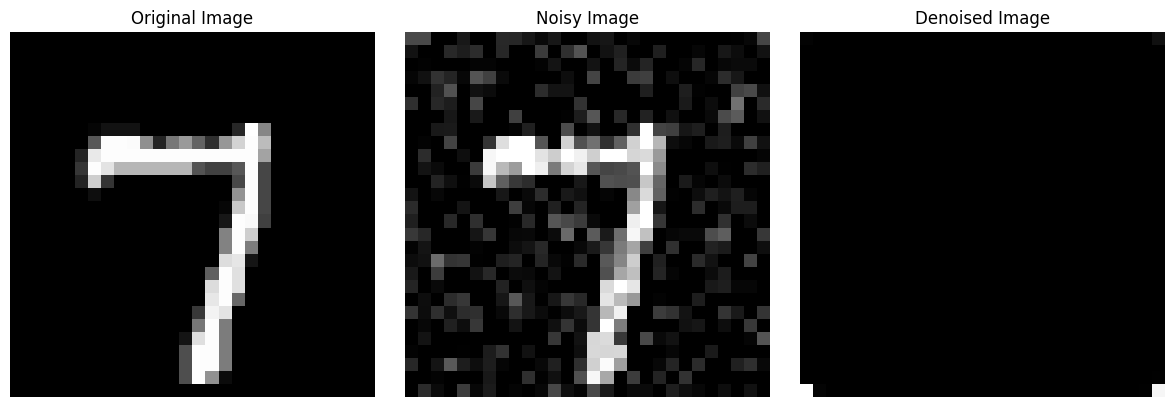

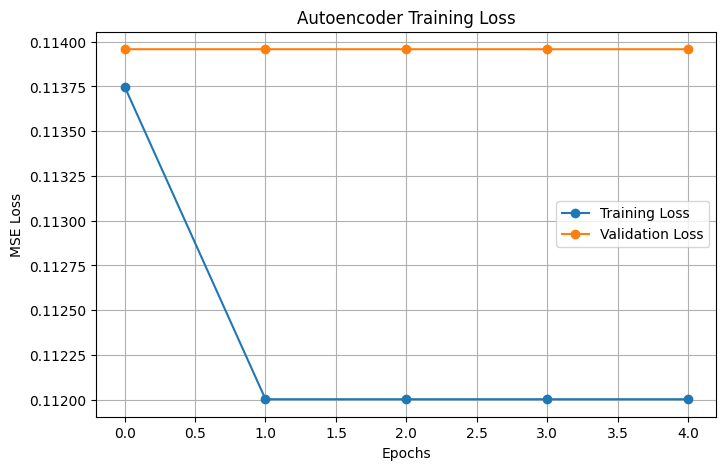


FINAL RESULT
Original Image Shape: (28, 28, 1)
Noisy Image MSE: 0.012611
Denoised Image MSE: 0.072521

Image Denoising Completed Successfully!


In [ ]:
# DLL Experiment No. 7
# Autoencoder for Image Denoising

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models


# 1. Load Predefined MNIST Dataset
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

print("Dataset Loaded Successfully!")
print("Training Images:", x_train.shape)
print("Testing Images:", x_test.shape)


# 2. Normalize Images
clean_images = x_train.astype("float32") / 255.0
test_images = x_test.astype("float32") / 255.0

# Add channel dimension
clean_images = np.expand_dims(clean_images, axis=-1)
test_images = np.expand_dims(test_images, axis=-1)

print("Image Shape:", clean_images.shape)


# 3. Generate Random Noise
np.random.seed(42)
tf.random.set_seed(42)

noise_factor = 0.15

train_noise = np.random.normal(
    loc=0.0,
    scale=noise_factor,
    size=clean_images.shape
).astype("float32")

test_noise = np.random.normal(
    loc=0.0,
    scale=noise_factor,
    size=test_images.shape
).astype("float32")


# Add noise to images
noisy_images = np.clip(
    clean_images + train_noise,
    0.0, 1.0
)

noisy_test_images = np.clip(
    test_images + test_noise,
    0.0, 1.0
)


# 4. Build Convolutional Autoencoder
autoencoder = models.Sequential([

    layers.Input(shape=(28, 28, 1)),

    # Encoder
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    # Decoder
    layers.UpSampling2D((2, 2)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.UpSampling2D((2, 2)),

    layers.Conv2D(
        1, (3, 3),
        activation="sigmoid",
        padding="same"
    )
])


# 5. Compile Autoencoder
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

print("\nAutoencoder Architecture:")
autoencoder.summary()


# 6. Train Autoencoder
print("\nTraining Autoencoder...")

history = autoencoder.fit(
    noisy_images,
    clean_images,
    validation_data=(noisy_test_images, test_images),
    epochs=5,
    batch_size=128,
    shuffle=True,
    verbose=1
)


# 7. Select Random Test Image
sample_index = np.random.randint(0, len(test_images))

original_image = test_images[sample_index]

noisy_image = noisy_test_images[sample_index]


# 8. Denoise Image
print("\nDenoising Image...")

denoised = autoencoder.predict(
    np.expand_dims(noisy_image, axis=0),
    verbose=0
)

denoised_image = denoised[0]


# 9. Calculate Reconstruction Error
mse = np.mean(
    (original_image - denoised_image) ** 2
)

noisy_mse = np.mean(
    (original_image - noisy_image) ** 2
)


# 10. Display Original, Noisy and Denoised Images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image.squeeze(), cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_image.squeeze(), cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(denoised_image.squeeze(), cmap="gray")
plt.title("Denoised Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# 11. Plot Training Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")

plt.legend()
plt.grid(True)
plt.show()


# 12. Final Results
print("\n================================")
print("FINAL RESULT")
print("================================")

print("Original Image Shape:", original_image.shape)

print("Noisy Image MSE:", round(float(noisy_mse), 6))

print("Denoised Image MSE:", round(float(mse), 6))

print("\nImage Denoising Completed Successfully!")

Saving images (1).jpg to images (1).jpg
Image Uploaded Successfully!
Image Shape: (128, 128, 3)


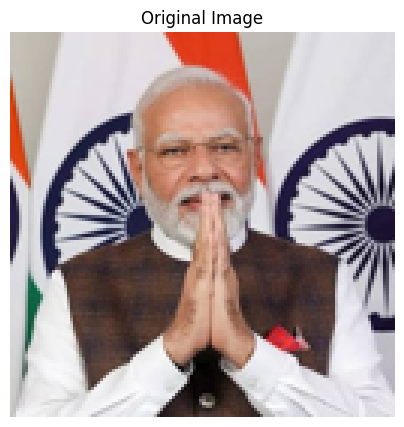

Training Images: (300, 128, 128, 3)

Autoencoder Architecture:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)


Training Autoencoder...
Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 326ms/step - loss: 0.0536
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0236
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0165
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0145
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0126
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0114
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0107
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0101
Epoch 9/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0095
Epoch 10/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0090

Denoising Image...


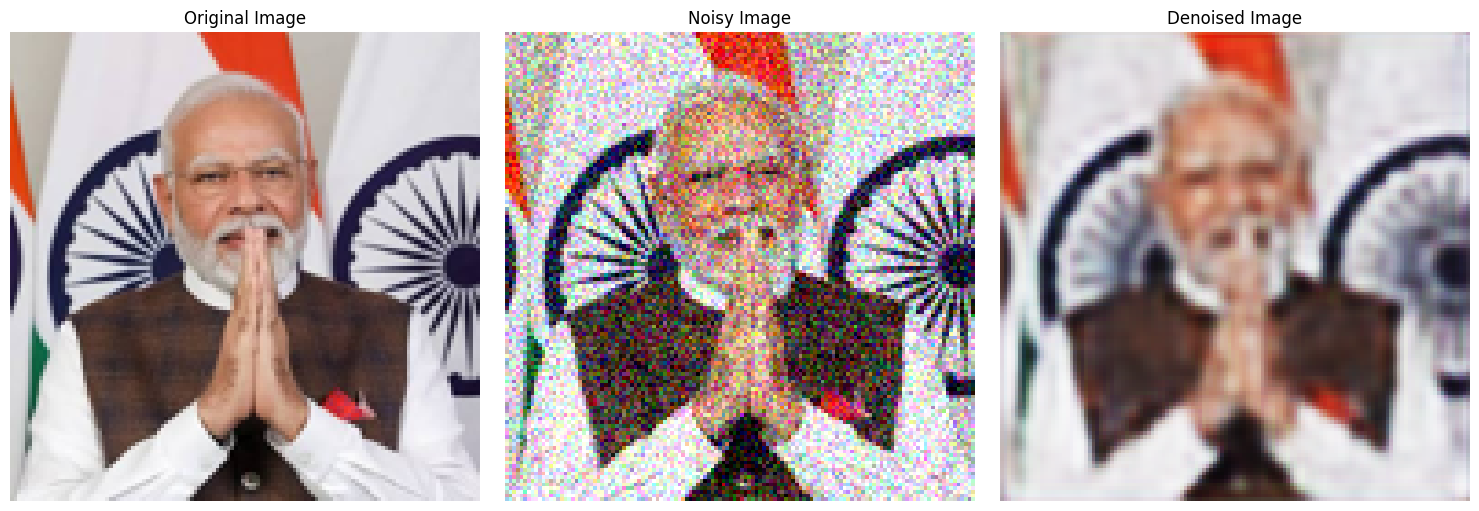

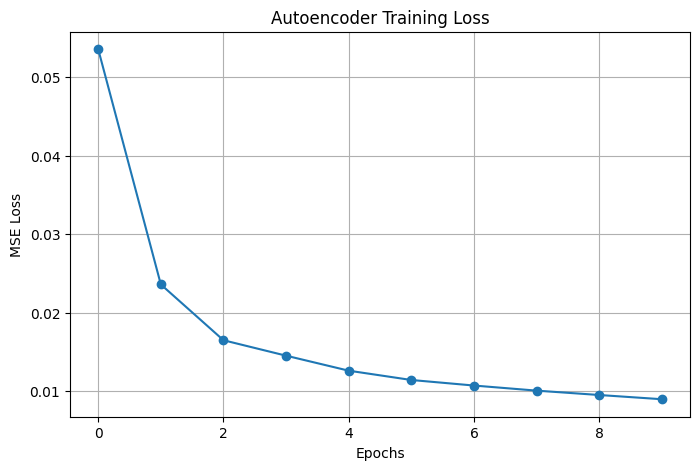


FINAL RESULT
Original Image Shape: (128, 128, 3)
Noisy Image MSE: 0.018191
Denoised Image MSE: 0.00871

Image Denoising Completed Successfully!


In [ ]:
# DLL Experiment No. 7
# Autoencoder for Image Denoising using Uploaded Image

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from google.colab import files
from PIL import Image


# 1. Upload Image
uploaded = files.upload()

filename = next(iter(uploaded))

image = Image.open(filename).convert("RGB")
image = image.resize((128, 128))

original = np.array(image).astype("float32") / 255.0

print("Image Uploaded Successfully!")
print("Image Shape:", original.shape)


# Display Original Image
plt.figure(figsize=(5, 5))
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")
plt.show()


# 2. Generate Noisy Training Images
np.random.seed(42)
tf.random.set_seed(42)

num_samples = 300
noise_factor = 0.15

clean_images = np.repeat(
    original[np.newaxis, ...],
    num_samples,
    axis=0
)

noise = np.random.normal(
    0,
    noise_factor,
    clean_images.shape
).astype("float32")

noisy_images = np.clip(
    clean_images + noise,
    0,
    1
)

print("Training Images:", noisy_images.shape)


# 3. Build Convolutional Autoencoder
autoencoder = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    # Encoder
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    # Decoder
    layers.UpSampling2D((2, 2)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.UpSampling2D((2, 2)),

    layers.Conv2D(
        3, (3, 3),
        activation="sigmoid",
        padding="same"
    )
])


# 4. Compile Autoencoder
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

print("\nAutoencoder Architecture:")
autoencoder.summary()


# 5. Train Autoencoder
print("\nTraining Autoencoder...")

history = autoencoder.fit(
    noisy_images,
    clean_images,
    epochs=10,
    batch_size=16,
    shuffle=True,
    verbose=1
)


# 6. Generate Noisy Test Image
test_noise = np.random.normal(
    0,
    noise_factor,
    original.shape
).astype("float32")

noisy_image = np.clip(
    original + test_noise,
    0,
    1
)


# 7. Denoise Image
noisy_input = np.expand_dims(
    noisy_image,
    axis=0
)

print("\nDenoising Image...")

denoised = autoencoder.predict(
    noisy_input,
    verbose=0
)

denoised_image = denoised[0]


# 8. Calculate MSE
noisy_mse = np.mean(
    (original - noisy_image) ** 2
)

denoised_mse = np.mean(
    (original - denoised_image) ** 2
)


# 9. Display Results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_image)
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(np.clip(denoised_image, 0, 1))
plt.title("Denoised Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# 10. Plot Training Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o"
)

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")

plt.grid(True)
plt.show()


# 11. Final Results
print("\n================================")
print("FINAL RESULT")
print("================================")

print("Original Image Shape:", original.shape)

print("Noisy Image MSE:", round(float(noisy_mse), 6))

print("Denoised Image MSE:", round(float(denoised_mse), 6))

print("\nImage Denoising Completed Successfully!")